<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB
       PassengerId    Survived      Pclass         Age       SibSp  \
count   891.000000  891.000000  891.000000  714.000000  891.000000   
mean    446.000000    0.383838    2.308642   29.699118    0.523008   
std     257.353842    0.486592    0.836071   14.5

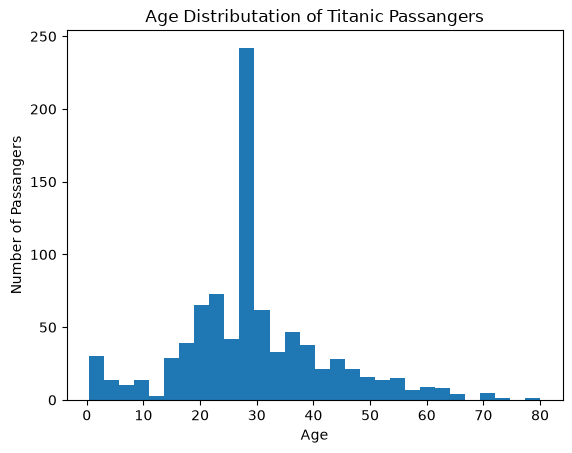

Cleaned dataset saved successfully!


In [3]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
import matplotlib.pyplot as plt


# Load dataset
df = pd.read_csv("Titanic-Dataset.csv")

# Basic information and statistics
df.info()
print(df.describe())

# Check missing values
print("\nMissing values before cleaning:")
print(df.isnull().sum())

# Handle missing values
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

# Drop Cabin because it has many missing values
df = df.drop("Cabin", axis=1)

# Label Encoding for Sex
label_encoder = LabelEncoder()
df["Sex"] = label_encoder.fit_transform(df["Sex"])

# One-Hot Encoding for Embarked
onehot_encoder = OneHotEncoder(
    sparse_output=False,
    handle_unknown="ignore"
)

embarked_encoded = onehot_encoder.fit_transform(df[["Embarked"]])

embarked_df = pd.DataFrame(
    embarked_encoded,
    columns=onehot_encoder.get_feature_names_out(["Embarked"]),
    index=df.index
)

# Add encoded columns to dataset
df = pd.concat([df, embarked_df], axis=1)

# Remove original Embarked column
df = df.drop("Embarked", axis=1)

# Check missing values after cleaning
print("\nMissing values after cleaning:")
print(df.isnull().sum())

# Display final dataset
df

#Age Distribution Graph

plt.hist(df["Age"], bins=30)

plt.title("Age Distributation of Titanic Passangers")
plt.xlabel("Age")
plt.ylabel("Number of Passangers")

plt.show()

#saving the file
df.to_csv("Titanic-Cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")